In [1]:
!pip install -q monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 55.3 MB/s eta 0:00:00


In [2]:
import os
import random
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from monai.networks.nets import DenseNet121


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

# ------------------------------------------------------------
# Kaggle paths
# ------------------------------------------------------------

PROCESSED_DIR = Path(
    "/kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset"
)

SPLIT_PATH = PROCESSED_DIR / "split_assignment.csv"
METADATA_PATH = PROCESSED_DIR / "metadata.csv"

# Separate output directories from the ResNet-18 run
CHECKPOINT_DIR = Path("/kaggle/working/checkpoints_densenet121")
RESULTS_DIR = Path("/kaggle/working/results_densenet121")

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

BATCH_SIZE = 4
NUM_WORKERS = 2

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 1e-5

GRAD_CLIP_MAX_NORM = 1.0

MAX_EPOCHS = 40

EARLY_STOPPING_PATIENCE = 7

LR_SCHEDULER_PATIENCE = 3
LR_SCHEDULER_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-6

AUGMENT_TRAIN = True

USE_WEIGHTED_SAMPLER = True

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ------------------------------------------------------------
# Print configuration
# ------------------------------------------------------------

print("=" * 70)
print("3D PDAC TRAINING — DENSENET-121 CONFIGURATION")
print("=" * 70)

print("Device        :", DEVICE)
print("Processed dir :", PROCESSED_DIR)
print("Split file    :", SPLIT_PATH)
print("Checkpoint dir:", CHECKPOINT_DIR)
print("Results dir   :", RESULTS_DIR)

print("\nSeed          :", SEED)
print("Batch size    :", BATCH_SIZE)
print("Workers       :", NUM_WORKERS)
print("Learning rate :", LEARNING_RATE)
print("Weight decay  :", WEIGHT_DECAY)
print("Grad clip norm:", GRAD_CLIP_MAX_NORM)
print("Weighted sampler:", USE_WEIGHTED_SAMPLER)
print("Max epochs    :", MAX_EPOCHS)
print("Early stopping:", EARLY_STOPPING_PATIENCE)

if DEVICE.type == "cuda":
    print("\nGPU           :", torch.cuda.get_device_name(0))
    print(
        "GPU memory    :",
        f"{torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB"
        if hasattr(torch.cuda.get_device_properties(0), 'total_mem')
        else f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB"
    )
else:
    print("\nWARNING: No CUDA GPU detected.")
    print("Do not start the full training run on CPU.")

print(
    "\nResNet-18 baseline to compare against: "
    "best val_loss=0.9166, test AUC=0.8556 (epoch 4)."
)

3D PDAC TRAINING — DENSENET-121 CONFIGURATION
Device        : cuda
Processed dir : /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset
Split file    : /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/split_assignment.csv
Checkpoint dir: /kaggle/working/checkpoints_densenet121
Results dir   : /kaggle/working/results_densenet121

Seed          : 42
Batch size    : 4
Workers       : 2
Learning rate : 5e-05
Weight decay  : 1e-05
Grad clip norm: 1.0
Weighted sampler: True
Max epochs    : 40
Early stopping: 7

GPU           : Tesla T4
GPU memory    : 15.6 GB

ResNet-18 baseline to compare against: best val_loss=0.9166, test AUC=0.8556 (epoch 4).


In [3]:
# ============================================================
# CELL 3 — LOAD PATIENT-LEVEL SPLIT
# ============================================================

split_df = pd.read_csv(SPLIT_PATH)

print("=" * 70)
print("SPLIT ASSIGNMENT")
print("=" * 70)
print("Columns:", list(split_df.columns))
print("Total cases:", len(split_df))
print("\nSplit distribution:")
print(split_df["split"].value_counts())

train_df = (
    split_df[split_df["split"].str.lower() == "train"]
    .reset_index(drop=True)
)

val_df = (
    split_df[
        split_df["split"].str.lower().isin(["validation", "val"])
    ]
    .reset_index(drop=True)
)

test_df = (
    split_df[split_df["split"].str.lower() == "test"]
    .reset_index(drop=True)
)

for name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    n_pdac = (df["diagnosis"] == "PDAC").sum()
    n_non = (df["diagnosis"] == "non-PDAC").sum()
    print(f"\n{name} cases: {len(df)} | PDAC: {n_pdac} | non-PDAC: {n_non}")

    # Class distribution
    print(f"\n{name} class distribution:")
    print(df["diagnosis"].value_counts())


SPLIT ASSIGNMENT
Columns: ['study_id', 'patient_id', 'diagnosis', 'image_path', 'mask_path', 'split']
Total cases: 2238

Split distribution:
split
train         1563
validation     338
test           337
Name: count, dtype: int64

Train cases: 1563 | PDAC: 473 | non-PDAC: 1090

Train class distribution:
diagnosis
non-PDAC    1090
PDAC         473
Name: count, dtype: int64

Validation cases: 338 | PDAC: 100 | non-PDAC: 238

Validation class distribution:
diagnosis
non-PDAC    238
PDAC        100
Name: count, dtype: int64

Test cases: 337 | PDAC: 103 | non-PDAC: 234

Test class distribution:
diagnosis
non-PDAC    234
PDAC        103
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 4 — PATIENT-LEVEL LEAKAGE AUDIT
# ============================================================

if "patient_id" not in split_df.columns:
    if not METADATA_PATH.exists():
        print("WARNING: metadata.csv not found.")
        print("Patient-level leakage audit cannot be completed automatically.")
    else:
        metadata_df = pd.read_csv(METADATA_PATH)

        if "study_id" in metadata_df.columns and "patient_id" in metadata_df.columns:
            patient_lookup = metadata_df[
                ["study_id", "patient_id"]
            ].drop_duplicates("study_id")

            split_df = split_df.merge(
                patient_lookup,
                on="study_id",
                how="left",
            )

            train_df = (
                split_df[split_df["split"].str.lower() == "train"]
                .reset_index(drop=True)
            )

            val_df = (
                split_df[
                    split_df["split"].str.lower().isin(["validation", "val"])
                ]
                .reset_index(drop=True)
            )

            test_df = (
                split_df[split_df["split"].str.lower() == "test"]
                .reset_index(drop=True)
            )


if "patient_id" in split_df.columns:

    print("=" * 70)
    print("PATIENT-LEVEL LEAKAGE AUDIT")
    print("=" * 70)

    train_patients = set(train_df["patient_id"].dropna().astype(str))
    val_patients = set(val_df["patient_id"].dropna().astype(str))
    test_patients = set(test_df["patient_id"].dropna().astype(str))

    train_val_overlap = train_patients & val_patients
    train_test_overlap = train_patients & test_patients
    val_test_overlap = val_patients & test_patients

    print("Train patients:", len(train_patients))
    print("Validation patients:", len(val_patients))
    print("Test patients:", len(test_patients))

    print("\nTrain ∩ Validation:", len(train_val_overlap))
    print("Train ∩ Test      :", len(train_test_overlap))
    print("Validation ∩ Test :", len(val_test_overlap))

    if train_val_overlap:
        raise ValueError("Patient leakage detected between train and validation.")
    if train_test_overlap:
        raise ValueError("Patient leakage detected between train and test.")
    if val_test_overlap:
        raise ValueError("Patient leakage detected between validation and test.")

    print("\n✓ No patient overlap detected.")

else:
    print(
        "WARNING: patient_id is unavailable, so patient-level leakage "
        "could not be audited automatically."
    )

PATIENT-LEVEL LEAKAGE AUDIT
Train patients: 1556
Validation patients: 332
Test patients: 336

Train ∩ Validation: 0
Train ∩ Test      : 0
Validation ∩ Test : 0

✓ No patient overlap detected.


In [5]:
for df in [train_df, val_df, test_df]:
    if df is not None:
        df["image_path"] = (
            "images/images/"
            + df["image_path"].astype(str).str.replace("\\", "/", regex=False).str.split("/").str[-1]
        )
        df["mask_path"] = (
            "masks/masks/"
            + df["mask_path"].astype(str).str.replace("\\", "/", regex=False).str.split("/").str[-1]
        )

In [6]:
# CELL 5 — DATASET PATH DIAGNOSTIC
# ============================================================

def show_path_diagnostic(df, name, n=3):
    print("=" * 70)
    print(f"{name} PATH DIAGNOSTIC")
    print("=" * 70)

    for _, row in df.head(n).iterrows():
        print(f"\nStudy ID: {row['study_id']}")

        image_path = PROCESSED_DIR / row["image_path"]
        mask_path = PROCESSED_DIR / row["mask_path"]

        print("\nResolved image path:", image_path)
        print("Image exists:", image_path.exists())

        print("\nResolved mask path:", mask_path)
        print("Mask exists:", mask_path.exists())

        if not image_path.exists() or not mask_path.exists():
            matches = list(PROCESSED_DIR.rglob(f"{row['study_id']}.npy"))
            print("\nPossible matches found via search:")
            for match in matches[:10]:
                print("  ", match)


show_path_diagnostic(train_df, "TRAIN")

# Hard stop if paths don't resolve
assert (PROCESSED_DIR / train_df.iloc[0]["image_path"]).exists(), (
    "First training image path did not resolve. Check the diagnostic "
    "output above before proceeding."
)
print("\n✓ Path check passed.")


TRAIN PATH DIAGNOSTIC

Study ID: 100000_00001

Resolved image path: /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/images/images/100000_00001.npy
Image exists: True

Resolved mask path: /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/masks/masks/100000_00001.npy
Mask exists: True

Study ID: 100001_00001

Resolved image path: /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/images/images/100001_00001.npy
Image exists: True

Resolved mask path: /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/masks/masks/100001_00001.npy
Mask exists: True

Study ID: 100002_00001

Resolved image path: /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/images/images/100002_00001.npy
Image exists: True

Resolved mask path: /kaggle/input/datasets/shahriarahmed66/panorama-processed-dataset/masks/masks/100002_00001.npy
Mask exists: True

✓ Path check passed.


In [7]:
# ============================================================
# CELL 6 — 3D DATASET
# ============================================================

class PDACVolumeDataset(Dataset):
    """
    Full-volume 3D CT dataset for binary PDAC classification.

    Expected image shape: (128, 160, 192), NumPy ordering (Z, Y, X).
    Returned tensor: (1, Z, Y, X).
    """

    def __init__(self, dataframe, processed_dir, augment=False):
        self.df = dataframe.reset_index(drop=True)
        self.processed_dir = Path(processed_dir)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = self.processed_dir / row["image_path"]

        volume = np.load(image_path).astype(np.float32)

        if volume.shape != (128, 160, 192):
            raise ValueError(
                f"Unexpected volume shape for {row['study_id']}: {volume.shape}"
            )
        if not np.isfinite(volume).all():
            raise ValueError(f"Non-finite values found in {row['study_id']}")

        if self.augment and np.random.random() < 0.5:
            volume = np.flip(volume, axis=2).copy()

        volume = np.expand_dims(volume, axis=0)  # (Z,H,W) -> (1,Z,H,W)

        label = 1.0 if row["diagnosis"] == "PDAC" else 0.0

        return (
            torch.from_numpy(volume),
            torch.tensor(label, dtype=torch.float32),
            row["study_id"],
        )


print("✓ PDACVolumeDataset defined.")


✓ PDACVolumeDataset defined.


In [8]:
# ============================================================
# CELL 7 — DATASETS AND DATALOADERS (WITH WEIGHTED SAMPLER)
# ============================================================

train_dataset = PDACVolumeDataset(train_df, PROCESSED_DIR, augment=AUGMENT_TRAIN)
val_dataset = PDACVolumeDataset(val_df, PROCESSED_DIR, augment=False)

test_dataset = None
if len(test_df) > 0:
    test_dataset = PDACVolumeDataset(test_df, PROCESSED_DIR, augment=False)


# ------------------------------------------------------------
# Weighted sampler for the training loader
# ------------------------------------------------------------

if USE_WEIGHTED_SAMPLER:
    class_counts = train_df["diagnosis"].value_counts()

    class_weight_map = {
        "PDAC": 1.0 / class_counts["PDAC"],
        "non-PDAC": 1.0 / class_counts["non-PDAC"],
    }

    sample_weights = train_df["diagnosis"].map(class_weight_map).values

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )

    print("Weighted sampler active.")
    print(f"  PDAC weight     : {class_weight_map['PDAC']:.6f}")
    print(f"  non-PDAC weight : {class_weight_map['non-PDAC']:.6f}")

else:
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )
    print("Weighted sampler disabled -- using plain shuffle.")


val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = None
if test_dataset is not None:
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )

print("\n" + "=" * 70)
print("DATA LOADERS")
print("=" * 70)
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader) if test_loader else "not available")

Weighted sampler active.
  PDAC weight     : 0.002114
  non-PDAC weight : 0.000917

DATA LOADERS
Train batches: 391
Val batches  : 85
Test batches : 85


In [9]:
# ============================================================
# CELL 8 — TRAINING BATCH SANITY CHECK
# ============================================================

volumes, labels, study_ids = next(iter(train_loader))

print("=" * 70)
print("BATCH SANITY CHECK")
print("=" * 70)
print("Volume tensor shape:", tuple(volumes.shape))
print("Volume dtype       :", volumes.dtype)
print("Labels             :", labels.tolist())
print("Study IDs          :", list(study_ids))
print("\nVolume min/max/mean/std:",
      volumes.min().item(), volumes.max().item(),
      volumes.mean().item(), volumes.std().item())

BATCH SANITY CHECK
Volume tensor shape: (4, 1, 128, 160, 192)
Volume dtype       : torch.float32
Labels             : [1.0, 1.0, 0.0, 0.0]
Study IDs          : ['100143_00001', '100267_00001', '100117_00001', '101153_00001']

Volume min/max/mean/std: 0.0 1.0 0.3033968508243561 0.3040545582771301


In [10]:
# ============================================================
# CELL 9 — 3D DENSENET-121 MODEL (MONAI)
# ============================================================
#
# This is the ONLY cell that differs from the ResNet-18 notebook.
#
# MONAI's DenseNet121 natively supports:
# - 3D spatial dimensions
# - Single-channel input (no RGB-to-grayscale hack needed)
# - Built-in dropout for regularization
#
# Architecture contrast:
# - ResNet-18:    residual ADDITION    [x + F(x)]
# - DenseNet-121: feature CONCATENATION [x, F(x)]
#
# DenseNet preserves fine-grained spatial gradients across all layers,
# which may produce sharper Grad-CAM saliency maps and better capture
# subtle PDAC textures in CT.

def build_model():
    model = DenseNet121(
        spatial_dims=3,
        in_channels=1,
        out_channels=1,
        dropout_prob=0.2,
    )
    return model


model = build_model().to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 70)
print("MODEL")
print("=" * 70)
print("Architecture      : 3D DenseNet-121 (MONAI)")
print("Pretraining       : None (trained from scratch)")
print("Input channels    : 1")
print("Output            : 1 binary logit")
print("Dropout           : 0.2")
print(f"Total parameters  : {n_params:,}")
print(f"Trainable params  : {trainable_params:,}")


MODEL
Architecture      : 3D DenseNet-121 (MONAI)
Pretraining       : None (trained from scratch)
Input channels    : 1
Output            : 1 binary logit
Dropout           : 0.2
Total parameters  : 11,243,649
Trainable params  : 11,243,649


In [11]:
# ============================================================
# CELL 10 — LOSS, OPTIMIZER, LR SCHEDULER, AMP
# ============================================================

train_pdac = int((train_df["diagnosis"] == "PDAC").sum())
train_non_pdac = int((train_df["diagnosis"] == "non-PDAC").sum())
pos_weight_value = train_non_pdac / max(train_pdac, 1)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(pos_weight_value, dtype=torch.float32, device=DEVICE)
)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_SCHEDULER_FACTOR,
    patience=LR_SCHEDULER_PATIENCE, min_lr=MIN_LEARNING_RATE,
)

scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

print("=" * 70)
print("OPTIMIZATION")
print("=" * 70)
print(f"PDAC cases       : {train_pdac}")
print(f"non-PDAC cases   : {train_non_pdac}")
print(f"pos_weight       : {pos_weight_value:.4f}")
print(f"learning rate    : {LEARNING_RATE}")
print(f"weight decay     : {WEIGHT_DECAY}")
print("\n✓ Optimizer, scheduler, loss, and AMP configured.")


OPTIMIZATION
PDAC cases       : 473
non-PDAC cases   : 1090
pos_weight       : 2.3044
learning rate    : 5e-05
weight decay     : 1e-05

✓ Optimizer, scheduler, loss, and AMP configured.


In [12]:
# ============================================================
# CELL 11 — CLASSIFICATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, f1_score, roc_auc_score,
)


def calculate_metrics(labels, probabilities, threshold=0.5):
    labels = np.asarray(labels).astype(int)
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    specificity = tn / max(tn + fp, 1)

    metrics = {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(labels, predictions, zero_division=0),
    }

    if len(np.unique(labels)) == 2:
        metrics["auc"] = roc_auc_score(labels, probabilities)
    else:
        metrics["auc"] = float("nan")

    return metrics


In [13]:
# ============================================================
# CELL 12 — TRAINING AND EVALUATION FUNCTIONS
# ============================================================

def train_one_epoch(model, loader, optimizer, criterion, scaler, device, max_grad_norm=None):
    model.train()
    running_loss = 0.0
    n_samples = 0
    epoch_start = time.time()

    for volumes, labels, _ in loader:
        volumes = volumes.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(volumes).squeeze(1)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()

        if max_grad_norm is not None:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * volumes.size(0)
        n_samples += volumes.size(0)

    elapsed = time.time() - epoch_start
    return running_loss / max(n_samples, 1), elapsed


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    n_samples = 0
    all_labels, all_probabilities, all_study_ids = [], [], []
    start = time.time()

    for volumes, labels, study_ids in loader:
        volumes = volumes.to(device, non_blocking=True)
        labels_device = labels.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(volumes).squeeze(1)
            loss = criterion(logits, labels_device)

        probabilities = torch.sigmoid(logits)

        running_loss += loss.item() * volumes.size(0)
        n_samples += volumes.size(0)

        all_labels.extend(labels.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())
        all_study_ids.extend(list(study_ids))

    avg_loss = running_loss / max(n_samples, 1)
    metrics = calculate_metrics(all_labels, all_probabilities, threshold=0.5)
    elapsed = time.time() - start

    return (
        avg_loss, metrics,
        np.asarray(all_labels), np.asarray(all_probabilities),
        all_study_ids, elapsed,
    )


In [14]:
# ============================================================
# CELL 13 — CHECKPOINT HELPERS
# ============================================================

LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_model.pt"


def save_checkpoint(path, model, optimizer, scheduler, scaler, epoch, best_val_loss, history):
    checkpoint = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "history": history,
        "seed": SEED,
    }
    torch.save(checkpoint, path)


def load_checkpoint(path, model, optimizer, scheduler, scaler, device):
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    scaler.load_state_dict(checkpoint["scaler_state"])
    return checkpoint["epoch"], checkpoint["best_val_loss"], checkpoint["history"]


print("✓ Checkpoint helpers defined.")

✓ Checkpoint helpers defined.


In [15]:
# ============================================================
# CELL 14 — RESUME PREVIOUS RUN WHEN AVAILABLE
# ============================================================

start_epoch = 1
best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "epoch": [], "train_loss": [], "val_loss": [],
    "val_accuracy": [], "val_precision": [], "val_recall": [],
    "val_specificity": [], "val_f1": [], "val_auc": [],
    "learning_rate": [], "train_time_sec": [], "val_time_sec": [],
}

if LATEST_CHECKPOINT.exists():
    print("=" * 70)
    print("RESUMING FROM CHECKPOINT")
    print("=" * 70)

    last_epoch, best_val_loss, history = load_checkpoint(
        LATEST_CHECKPOINT, model, optimizer, scheduler, scaler, DEVICE,
    )
    start_epoch = last_epoch + 1

    print("Last completed epoch:", last_epoch)
    print("Next epoch:", start_epoch)
    print("Best validation loss:", best_val_loss)
else:
    print("No previous checkpoint found in this session. Starting a new training run.")

No previous checkpoint found in this session. Starting a new training run.


In [36]:
# ============================================================
# CELL 15 — FINAL 3D TRAINING LOOP
# ============================================================

if DEVICE.type != "cuda":
    raise RuntimeError(
        "A CUDA GPU is required for the final training run. "
        "Enable a Kaggle GPU accelerator."
    )

print("=" * 70)
print("STARTING 3D DENSENET-121 TRAINING")
print("=" * 70)
print(f"Train cases: {len(train_dataset)}")
print(f"Val cases  : {len(val_dataset)}")
if test_dataset is not None:
    print(f"Test cases : {len(test_dataset)}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Starting epoch: {start_epoch}")

training_start = time.time()

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    epoch_start = time.time()

    train_loss, train_time = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, DEVICE,
        max_grad_norm=GRAD_CLIP_MAX_NORM,
    )
    val_loss, val_metrics, _, _, _, val_time = evaluate(
        model, val_loader, criterion, DEVICE,
    )

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_precision"].append(val_metrics["precision"])
    history["val_recall"].append(val_metrics["recall"])
    history["val_specificity"].append(val_metrics["specificity"])
    history["val_f1"].append(val_metrics["f1"])
    history["val_auc"].append(val_metrics["auc"])
    history["learning_rate"].append(current_lr)
    history["train_time_sec"].append(train_time)
    history["val_time_sec"].append(val_time)

    # Save latest checkpoint after EVERY epoch.
    save_checkpoint(
        LATEST_CHECKPOINT, model, optimizer, scheduler, scaler,
        epoch, best_val_loss, history,
    )

    # Save best model separately.
    if improved:
        torch.save(
            {
                "epoch": epoch,
                "model_state": copy.deepcopy(model.state_dict()),
                "best_val_loss": best_val_loss,
                "val_metrics": val_metrics,
            },
            BEST_CHECKPOINT,
        )

    epoch_total_time = train_time + val_time

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"val_auc={val_metrics['auc']:.4f} | val_f1={val_metrics['f1']:.4f} | "
        f"lr={current_lr:.2e} | epoch_time={epoch_total_time:.1f}s"
    )

    if improved:
        print("  ✓ New best validation checkpoint saved.")

    print(f"  No improvement for {epochs_without_improvement} epoch(s).")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\n" + "-" * 70)
        print(f"Early stopping triggered after {epoch} epochs.")
        print("-" * 70)
        break

total_training_hours = (time.time() - training_start) / 3600

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print(f"Total training time: {total_training_hours:.2f} GPU-hours")
print("Best validation loss:", best_val_loss)
print("Best checkpoint:", BEST_CHECKPOINT)

STARTING 3D DENSENET-121 TRAINING
Train cases: 1563
Val cases  : 338
Test cases : 337
Maximum epochs: 40
Starting epoch: 1
Epoch 01/40 | train_loss=0.8668 | val_loss=0.9861 | val_auc=0.7729 | val_f1=0.5608 | lr=6.25e-06 | epoch_time=153.1s
  No improvement for 8 epoch(s).

----------------------------------------------------------------------
Early stopping triggered after 1 epochs.
----------------------------------------------------------------------

TRAINING COMPLETE
Total training time: 0.04 GPU-hours
Best validation loss: 0.8629030435395664
Best checkpoint: /kaggle/working/checkpoints_densenet121/best_model.pt


In [37]:
# ============================================================
# CELL 16 — SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)
history_path = RESULTS_DIR / "training_history.csv"
history_df.to_csv(history_path, index=False)

print("Saved:", history_path)
print("\nLast training records:")
print(history_df.tail())

Saved: /kaggle/working/results_densenet121/training_history.csv

Last training records:
    epoch  train_loss  val_loss  val_accuracy  val_precision  val_recall  \
20      6    0.830594  0.960812      0.727811       0.529412        0.72   
21      7    0.860426  0.966170      0.701183       0.496732        0.76   
22      8    0.828005  1.105316      0.698225       0.493827        0.80   
23      9    0.830659  1.097623      0.710059       0.507812        0.65   
24      1    0.866782  0.986053      0.615385       0.423469        0.83   

    val_specificity    val_f1   val_auc  learning_rate  train_time_sec  \
20         0.731092  0.610169  0.788971       0.000013      143.021196   
21         0.676471  0.600791  0.781513       0.000013      142.980693   
22         0.655462  0.610687  0.792878       0.000013      143.316243   
23         0.735294  0.570175  0.757668       0.000013      142.987243   
24         0.525210  0.560811  0.772857       0.000006      143.216664   

    val_ti

Saved: /kaggle/working/results_densenet121/training_validation_loss.png


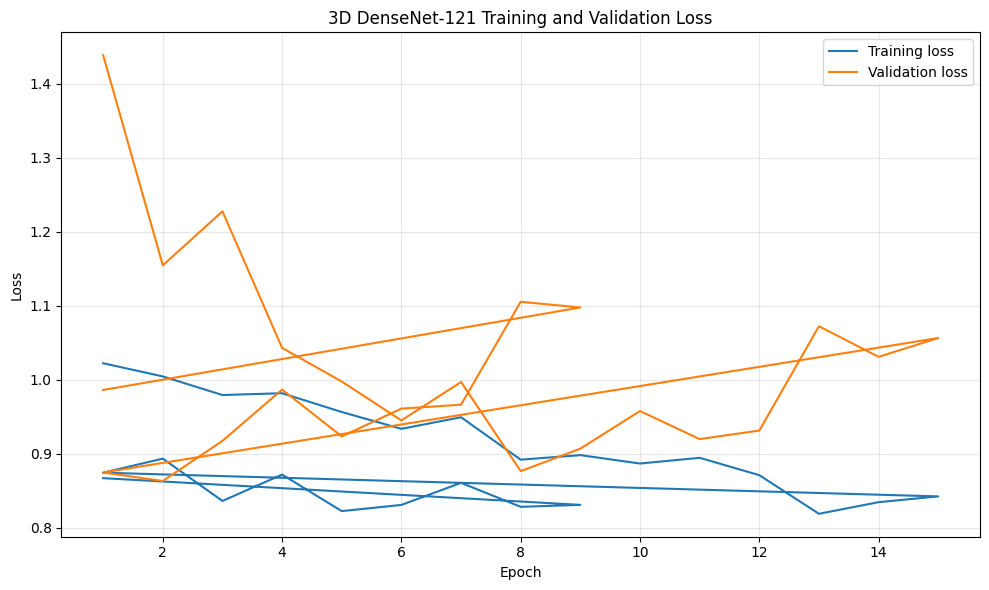

In [38]:
# ============================================================
# CELL 17 — TRAINING AND VALIDATION LOSS PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history_df["epoch"], history_df["train_loss"], label="Training loss")
ax.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("3D DenseNet-121 Training and Validation Loss")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = RESULTS_DIR / "training_validation_loss.png"
fig.savefig(loss_plot_path, dpi=150, bbox_inches="tight")
print("Saved:", loss_plot_path)
plt.show()



Saved: /kaggle/working/results_densenet121/validation_metrics.png


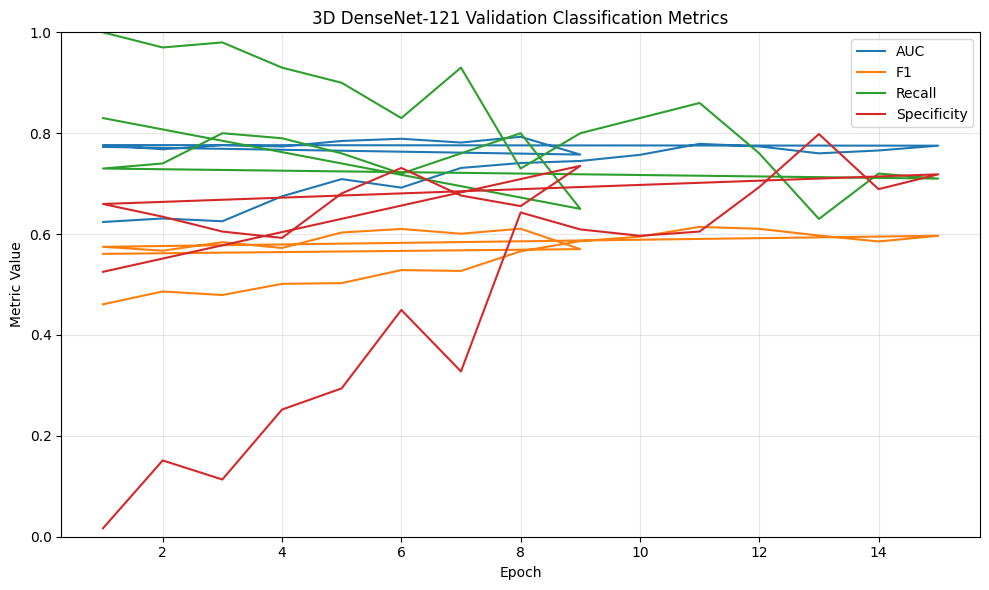

In [39]:
# ============================================================
# CELL 18 — VALIDATION METRICS PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history_df["epoch"], history_df["val_auc"], label="AUC")
ax.plot(history_df["epoch"], history_df["val_f1"], label="F1")
ax.plot(history_df["epoch"], history_df["val_recall"], label="Recall")
ax.plot(history_df["epoch"], history_df["val_specificity"], label="Specificity")
ax.set_xlabel("Epoch")
ax.set_ylabel("Metric Value")
ax.set_title("3D DenseNet-121 Validation Classification Metrics")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0.0, 1.0)
plt.tight_layout()

metrics_plot_path = RESULTS_DIR / "validation_metrics.png"
fig.savefig(metrics_plot_path, dpi=150, bbox_inches="tight")
print("Saved:", metrics_plot_path)
plt.show()

In [40]:
# ============================================================
# CELL 19 — LOAD BEST VALIDATION CHECKPOINT
# ============================================================

if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found:\n{BEST_CHECKPOINT}"
    )

best_checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint["model_state"]
)

model.eval()

print("=" * 70)
print("BEST MODEL LOADED")
print("=" * 70)

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best validation loss:",
    best_checkpoint["best_val_loss"]
)

print(
    "Stored validation metrics:",
    best_checkpoint["val_metrics"]
)


BEST MODEL LOADED
Best epoch: 2
Best validation loss: 0.8629030435395664
Stored validation metrics: {'accuracy': 0.665680473372781, 'precision': 0.45962732919254656, 'recall': 0.74, 'specificity': np.float64(0.634453781512605), 'f1': 0.5670498084291188, 'auc': np.float64(0.7681302521008404)}


In [41]:
# ============================================================
# CELL 20 — FINAL VALIDATION EVALUATION
# ============================================================

(val_loss, val_metrics, val_labels, val_probabilities,
 val_study_ids, val_eval_time) = evaluate(model, val_loader, criterion, DEVICE)

print("=" * 70)
print("BEST MODEL — VALIDATION RESULTS")
print("=" * 70)
print(f"Validation loss : {val_loss:.4f}")
print(f"Accuracy        : {val_metrics['accuracy']:.4f}")
print(f"Precision       : {val_metrics['precision']:.4f}")
print(f"Recall          : {val_metrics['recall']:.4f}")
print(f"Specificity     : {val_metrics['specificity']:.4f}")
print(f"F1              : {val_metrics['f1']:.4f}")
print(f"ROC-AUC         : {val_metrics['auc']:.4f}")


BEST MODEL — VALIDATION RESULTS
Validation loss : 0.8629
Accuracy        : 0.6657
Precision       : 0.4596
Recall          : 0.7400
Specificity     : 0.6345
F1              : 0.5670
ROC-AUC         : 0.7681


In [42]:
# ============================================================
# CELL 21 — FINAL TEST EVALUATION
# ============================================================

if test_loader is None:
    print("=" * 70)
    print("NO TEST SPLIT AVAILABLE")
    print("=" * 70)
    print(
        "The split file does not contain an independent test split. "
        "Do not describe the validation set as a test set."
    )
else:
    (test_loss, test_metrics, test_labels, test_probabilities,
     test_study_ids, test_eval_time) = evaluate(model, test_loader, criterion, DEVICE)

    print("=" * 70)
    print("FINAL TEST RESULTS")
    print("=" * 70)
    print(f"Test loss       : {test_loss:.4f}")
    print(f"Accuracy        : {test_metrics['accuracy']:.4f}")
    print(f"Precision       : {test_metrics['precision']:.4f}")
    print(f"Recall          : {test_metrics['recall']:.4f}")
    print(f"Specificity     : {test_metrics['specificity']:.4f}")
    print(f"F1              : {test_metrics['f1']:.4f}")
    print(f"ROC-AUC         : {test_metrics['auc']:.4f}")


FINAL TEST RESULTS
Test loss       : 0.8322
Accuracy        : 0.6617
Precision       : 0.4675
Recall          : 0.7670
Specificity     : 0.6154
F1              : 0.5809
ROC-AUC         : 0.7828


In [43]:
# ============================================================
# CELL 22 — SAVE MODEL PREDICTIONS
# ============================================================

val_predictions_df = pd.DataFrame({
    "study_id": val_study_ids,
    "label": val_labels.astype(int),
    "probability": val_probabilities,
})
val_predictions_path = RESULTS_DIR / "validation_predictions.csv"
val_predictions_df.to_csv(val_predictions_path, index=False)
print("Validation predictions saved:", val_predictions_path)

if test_loader is not None:
    test_predictions_df = pd.DataFrame({
        "study_id": test_study_ids,
        "label": test_labels.astype(int),
        "probability": test_probabilities,
    })
    test_predictions_path = RESULTS_DIR / "test_predictions.csv"
    test_predictions_df.to_csv(test_predictions_path, index=False)
    print("Test predictions saved:", test_predictions_path)


Validation predictions saved: /kaggle/working/results_densenet121/validation_predictions.csv
Test predictions saved: /kaggle/working/results_densenet121/test_predictions.csv


In [44]:
# ============================================================
# CELL 23 — SAVE SPLIT FILE COPY FOR DOWNSTREAM NOTEBOOKS
# ============================================================

# Save a copy of the split assignment so Grad-CAM and calibration
# notebooks can access it without needing the original dataset attached.
split_copy_path = RESULTS_DIR / "split_assignment.csv"
split_df.to_csv(split_copy_path, index=False)
print("Split assignment copy saved:", split_copy_path)


Split assignment copy saved: /kaggle/working/results_densenet121/split_assignment.csv


In [45]:
# ============================================================
# CELL 24 — FINAL EXPERIMENT RECORD
# ============================================================

experiment_record = {
    "seed": SEED,
    "architecture": "3D DenseNet-121",
    "pretraining": "None (from scratch)",
    "input_shape": "(1, 128, 160, 192)",
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout_prob": 0.2,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "train_cases": len(train_df),
    "validation_cases": len(val_df),
    "test_cases": len(test_df),
    "best_epoch": int(best_checkpoint["epoch"]),
    "best_validation_loss": float(best_checkpoint["best_val_loss"]),
}

experiment_record_df = pd.DataFrame([experiment_record])
record_path = RESULTS_DIR / "experiment_record.csv"
experiment_record_df.to_csv(record_path, index=False)

print("=" * 70)
print("EXPERIMENT RECORD")
print("=" * 70)
for key, value in experiment_record.items():
    print(f"{key}: {value}")
print("\nSaved:", record_path)

# %% [markdown]
# ## Training conclusion
#
# The 3D DenseNet-121 PDAC classification model was trained using full
# preprocessed pancreas-centered CT volumes, on the **exact same
# patient-level split** as the 3D ResNet-18 baseline.
#
# The saved predictions and best checkpoint provide the inputs required
# for the subsequent:
#
# 1. classification performance comparison with ResNet-18,
# 2. calibration analysis and temperature scaling,
# 3. reliability diagrams,
# 4. 3D Grad-CAM generation (targeting `model.features.denseblock4`), and
# 5. quantitative explanation evaluation against the expert PDAC tumor mask.
#
# The architectural comparison (ResNet addition vs. DenseNet concatenation)
# directly tests whether the trustworthiness findings from Model 1
# (overconfidence, saliency failure) are architecture-specific or general.


EXPERIMENT RECORD
seed: 42
architecture: 3D DenseNet-121
pretraining: None (from scratch)
input_shape: (1, 128, 160, 192)
batch_size: 4
learning_rate: 5e-05
weight_decay: 1e-05
dropout_prob: 0.2
max_epochs: 40
early_stopping_patience: 7
train_cases: 1563
validation_cases: 338
test_cases: 337
best_epoch: 2
best_validation_loss: 0.8629030435395664

Saved: /kaggle/working/results_densenet121/experiment_record.csv
